# Implementation of Ridge Regularization (L2) for 2d [1 i/p, 1 o/p]

In [245]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score
from sklearn.datasets import make_regression

In [246]:
X, y = make_regression(n_samples=100, n_features=1, n_targets=1, n_informative=1, noise = 20, random_state=42)

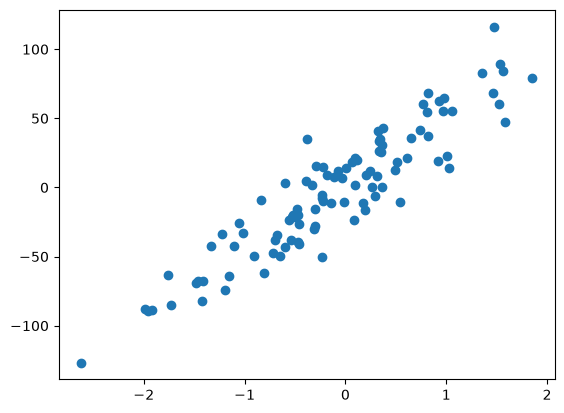

In [247]:
plt.scatter(X, y)

In [248]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Getting results using built-in classes [for alpha = 0, 10, 100]

In [249]:
model1 = LinearRegression() # or Ridge(alpha = 0)
model1.fit(X_train, y_train)
print(model1.intercept_, model1.coef_)

0.19844442845175525 [46.747264]


In [250]:
y_pred = model1.predict(X_test)
r2_score(y_test, y_pred)

0.8019015156159199

In [251]:
model2 = Ridge(alpha=10)
model2.fit(X_train, y_train)
print(model2.intercept_, model2.coef_)

-0.598950580780321 [40.54930462]


In [252]:
y_pred = model2.predict(X_test)
r2_score(y_test, y_pred)

0.7762183992232433

In [253]:
model3 = Ridge(alpha=100)
model3.fit(X_train, y_train)
print(model3.intercept_, model3.coef_)

-3.437216892448689 [18.48814411]


In [254]:
y_pred = model3.predict(X_test)
r2_score(y_test, y_pred)

0.44346338870838586

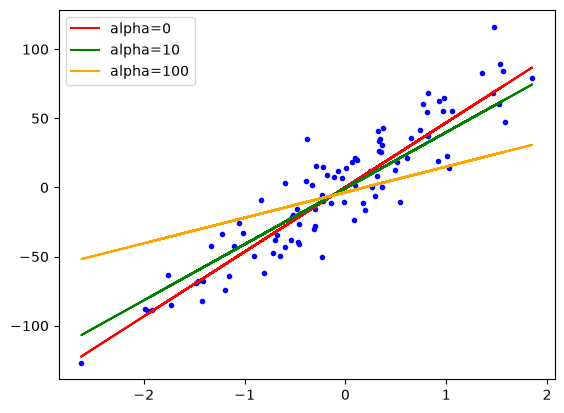

In [255]:
plt.plot(X,y,'b.')
plt.plot(X,model1.predict(X),color='red',label='alpha=0')
plt.plot(X,model2.predict(X),color='green',label='alpha=10')
plt.plot(X,model3.predict(X),color='orange',label='alpha=100')
plt.legend()

# Building the Ridge class of sklearn

In [256]:
class RidgeRegularization:

    def __init__(self, alpha = 1):
        self.intercept_ = None
        self.coef_ = None
        self.alpha = alpha

    def fit(self, X_train, X_test):

        coef_numerator = 0
        coef_denominator = 0

        for i in range(X_train.shape[0]):

            coef_numerator += (y_train[i] - y_train.mean()) * (X_train[i] - X_train.mean())
            coef_denominator += (X_train[i] - X_train.mean()) ** 2

        self.coef_ = coef_numerator / (self.alpha + coef_denominator)
        self.intercept_ = np.mean(y_train) - self.coef_ * np.mean(X_train)

    def predict(self, X_test):
        return self.coef_*X_test + self.intercept_

In [257]:
model4 = RidgeRegularization(alpha = 10)
model4.fit(X_train, y_train)
print(model4.intercept_, model4.coef_)

[-0.59895058] [40.54930462]


In [258]:
y_pred = model4.predict(X_test)
r2_score(y_test, y_pred)

0.7762183992232431

In [259]:
# done :)